# Pseudomode mapping for SIAM 

## Introduction

This notebook applies the approach of (Pleasance et al) to simulate the reduced system dynamics of the noninteracting single impurity Anderson model (SIAM). 

The Hamiltonian of the SIAM is given by ($\hbar=k_B=1$) 
\begin{align*}
    H &= \varepsilon_0(c^{\dagger}_{\uparrow}c_{\uparrow} + c^{\dagger}_{\downarrow}c_{\downarrow}) + Uc^{\dagger}_{\uparrow}c_{\uparrow}c^{\dagger}_{\downarrow}c_{\downarrow} \\
      &\qquad\quad + \sum_k\Big[\varepsilon_kd^{\dagger}_{k}d_{k} + \sum_{\sigma\in\{\uparrow,\downarrow\}}(t^*_kc^{\dagger}_{\sigma}d_{k} + t_kd^{\dagger}_{k}c_{\sigma}).\Big] 
\end{align*}
Here, $c_{\sigma }$ ($c^{\dagger}_{\sigma }$) is the fermionic annihilation (creation) operator of the impurity $S$ of spin $\sigma$, $d_{k}$ ($d^{\dagger}_{k}$) is the fermionic annihilation (creation) operator of the $k$-th bath mode of frequency $\varepsilon_k$, and $t_k$ denotes the impurity-contiuum tunneling strength. 

Assuming a bath $B$ at fixed temperature $T=\frac{1}{\beta}$ and chemical potential $\mu$, the BCFs are given by
\begin{align*}
  C^{>B}(t) &= \int^{\infty}_{-\infty}\frac{d\omega}{2\pi}\Gamma(\omega)[1 - n^{\rm F}_{\beta}(\omega-\mu)]e^{-i\omega t}, \\ 
  C^{<B}(t) &= \int^{\infty}_{-\infty}\frac{d\omega}{2\pi}\Gamma(\omega)n^{\rm F}_{\beta}(\omega-\mu)e^{i\omega t},
\end{align*}
where $\Gamma(\omega) = 2\pi\sum_k|t_k|^2\delta(\omega - \varepsilon_k)$ is the bath hybridization function (spectral density), and $n^{\rm F}_{\beta}(\omega) = 1/(e^{\beta\omega}+1)$.

In the following we assume a Lorentzian hybridization function
\begin{equation*}
  \Gamma(\omega) = \frac{V^2 W}{(\omega - \mu)^2 + W^2}.
\end{equation*}

Using contour integration techniques, the BCFs can be analytically determined as 
\begin{align*}
  C^{>B}(t) &= \frac{V^2}{4}\Big[1 - i\tan{\Big(\frac{\beta W}{2}\Big)}\Big]e^{-i\mu t - W|t|} - \frac{i}{\beta}\sum^{\infty}_{n=0}\frac{V^2W}{W^2-\nu^2_n}e^{-i\mu t - \nu_n|t|},    \\ 
  C^{<B}(t) &= \frac{V^2}{2}n^{\rm F}_{\beta}(iW)e^{i\mu t - W|t|} - \frac{i}{\beta}\sum^{\infty}_{n=0}\frac{V^2W}{W^2-\nu^2_n}e^{i\mu t - \nu_n|t|},
\end{align*}
with $\nu_n = \frac{(2n+1)\pi}{\beta}$ ($n\in\mathbb{Z}$) the fermionic Matsubara frequencies, and $C^{B\gtrless}(-t) = C^{B\gtrless}(t)^*$.  

In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl 

In [2]:
# Parameters (units of impurity site energy e0)
T = 0.25
mu = 1.0
lmb = 0.5 
W = 0.1

tlist = np.linspace(0, 40, 500)
wlist = np.linspace(-5+mu, 5+mu, 500)

### Preliminaries

We first benchmark the bcf_lorenztian() function against its QuTiP counterpart for a Lorentzian bath:

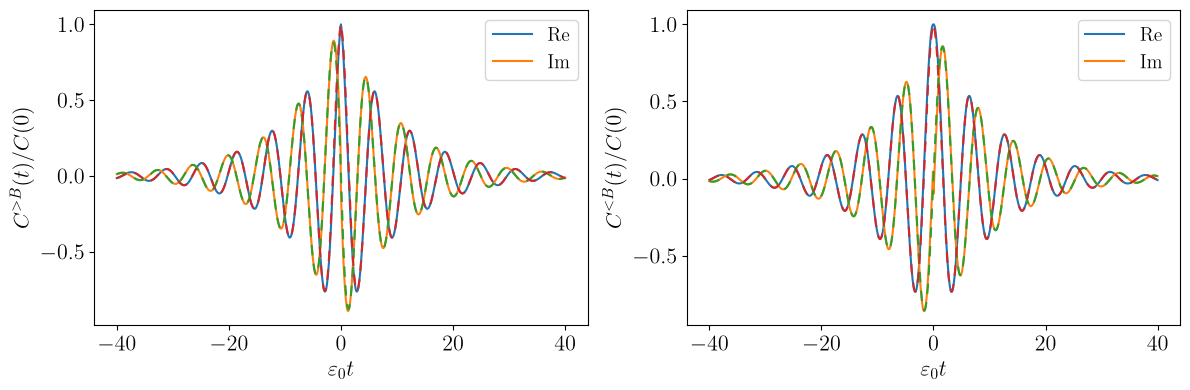

In [3]:
from pseudomodes.siam import bcf_lorentzian

# Plots of greater and lesser bcfs 
mpl.rcParams['axes.labelsize'] = 16
mpl.rcParams['xtick.labelsize'] = 16
mpl.rcParams['ytick.labelsize'] = 16
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.titlesize'] = 15
mpl.rcParams['text.usetex'] = True

# Positive + negative times
tlist_pn = np.concatenate((-np.flip(tlist),tlist), axis=0)

fig0, ax0 = plt.subplots(1,2,figsize=(12,4))

bath = qt.LorentzianEnvironment(T=T, mu=mu, gamma=lmb**2/W, W=W, omega0=mu, Nk=100)

#c0 = np.real(bcf_lorentzian(tlist, T=T, coup=lmb, width=W, w_res=mu, Nk=100)[0])
c0 = np.real(bath.correlation_function_minus(tlist)[0])

# C^{>B}(t)
ax0[0].plot(tlist_pn, np.real(bcf_lorentzian(tlist_pn, T=T, coup=lmb, width=W, w_res=mu, Nk=100)) / c0, label=r'$\mathrm{Re}$')
ax0[0].plot(tlist_pn, np.imag(bcf_lorentzian(tlist_pn, T=T, coup=lmb, width=W, w_res=mu, Nk=100)) / c0, label=r'$\mathrm{Im}$')
ax0[0].plot(tlist_pn, np.imag(bath.correlation_function_minus(tlist_pn)) / c0, linestyle=(0, (5, 4)))
ax0[0].plot(tlist_pn, np.real(bath.correlation_function_minus(tlist_pn)) / c0, linestyle=(0, (5, 4)))

ax0[0].legend(loc=0)
ax0[0].set_xlabel(r'$\varepsilon_0 t$')
ax0[0].set_ylabel(r'$C^{>B}(t) / C(0)$')

# C^{<B}(t) 
ax0[1].plot(tlist_pn, np.real(bcf_lorentzian(tlist_pn, T=T, coup=lmb, width=W, w_res=mu, Nk=100, bcf_type='less')) / c0, label=r'$\mathrm{Re}$')
ax0[1].plot(tlist_pn, np.imag(bcf_lorentzian(tlist_pn, T=T, coup=lmb, width=W, w_res=mu, Nk=100, bcf_type='less')) / c0, label=r'$\mathrm{Im}$')
ax0[1].plot(tlist_pn, np.imag(bath.correlation_function_plus(tlist_pn)) / c0, linestyle=(0, (5, 4)))
ax0[1].plot(tlist_pn, np.real(bath.correlation_function_plus(tlist_pn)) / c0, linestyle=(0, (5, 4)))

ax0[1].legend(loc=0)
ax0[1].set_xlabel(r'$\varepsilon_0 t$')
ax0[1].set_ylabel(r'$C^{<B}(t) / C(0)$')

fig0.tight_layout()
plt.show()


## Fitting of bath correlation functions

The PM parameters are extracted through first fitting the following bath ansatze to $C^{>B}(t)$ and $C^{<B}(t)$:
\begin{align*}
    C^{>E}(t) &= -i\theta(t)\sum^{N_L}_{l=1}r_{Ll}e^{-iz_{Ll}t} + i\theta(-t)\sum^{N_L}_{l=1}r^*_{Ll}e^{iz^*_{Ll}|t|}, \\
    C^{<E}(t) &= i\theta(t)\sum^{N_R}_{l=1}r^*_{Rl}e^{iz^*_{Rl}t} - i\theta(-t)\sum^{N_R}_{l=1}r_{Rl}e^{-iz_{Rl}|t|},
\end{align*} 
where $\theta(t)$ is the Heaviside step function, and $z_{jl} = {\rm Re}(z_{jl}) - i\,{\rm Im}(z_{jl})$. The corresponding noise spectra are given by
\begin{align*}
    {\gamma^{>}}'(\omega) &= 2\,{\rm Im}[\boldsymbol{g}^T_L(\boldsymbol{\Lambda}_L - \omega)^{-1}\boldsymbol{g}_L], \\
    {\gamma^{<}}'(\omega) &= -2\,{\rm Im}[\boldsymbol{g}^{T}_R(\boldsymbol{\Lambda}^*_R - \omega)^{-1}\boldsymbol{g}_R],
\end{align*}
with $\boldsymbol{g}_j = (\sqrt{-ir_{j1}}, ..., \sqrt{-ir_{jN}})^T$ and $\boldsymbol{\Lambda}_j = {\rm diag}(z_{j1},...,z_{jN})$.

As per notebook [pm_underdamped.ipynb](pm_underdamped.ipynb), we quantity the error in the fitting using the measures
\begin{equation*}
    \Delta C^{\gtrless}(t) = |C^{\gtrless B}(t) - C^{\gtrless E}(t)|,
\end{equation*}
and 
\begin{equation*}
    \Delta\gamma^{\gtrless}(\omega) = |\gamma^{\gtrless}(\omega) - {\gamma^{\gtrless}}'(\omega)|.
\end{equation*}

In [4]:
from pseudomodes.fitting import bcf_fit_params_fermion

# NEED TO FIX bcf_lorentzian

#bcf_gtr = bcf_lorentzian(tlist, T=T, coup=lmb, width=W, w_res=mu, Nk=100)
bcf_gtr = bath.correlation_function_minus(tlist_pn)
#bcf_less = bcf_lorentzian(tlist, T=T, coup=lmb, width=W, w_res=mu, Nk=100, bcf_type='less')
bcf_less = bath.correlation_function_plus(tlist_pn)

gL, LmbL = bcf_fit_params_fermion(tlist_pn, bcf=bcf_gtr, init_params=([1],[1],[1,-1],[1,1]), C0=c0, bcf_type='gtr')
gR, LmbR = bcf_fit_params_fermion(tlist_pn, bcf=bcf_less, init_params=([1],[1],[1,-1],[1,1]), C0=c0, bcf_type='less')

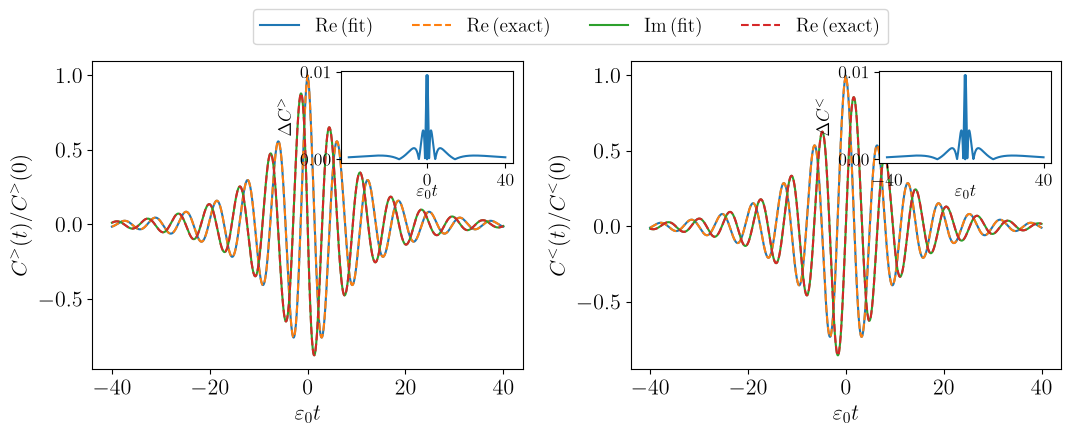

In [5]:
from pseudomodes.fitting import bcf_fit_gtr, bcf_fit_less
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig1, ax1 = plt.subplots(1,2, figsize=(12.5,4))

# Greater
ax1[0].plot(tlist_pn, np.real(bcf_fit_gtr(tlist_pn, gL, LmbL)) / c0, label=r'$\mathrm{Re \, (fit)}$')
ax1[0].plot(tlist_pn, np.real(bcf_gtr) / c0, linestyle='--', label=r'$\mathrm{Re \, (exact)}$')
ax1[0].plot(tlist_pn, np.imag(bcf_fit_gtr(tlist_pn, gL, LmbL)) / c0, label=r'$\mathrm{Im \, (fit)}$')
ax1[0].plot(tlist_pn, np.imag(bcf_gtr) / c0, linestyle='--', label=r'$\mathrm{Re  \, (exact)}$')

ax1[0].set_ylabel(r'$C^{>}(t) / C^{>}(0)$')
ax1[0].set_xlabel(r'$\varepsilon_0 t$')

# Error - greater
bcf_gtr_err = np.abs(bcf_gtr - bcf_fit_gtr(tlist_pn, gL, LmbL))

ax1_inset_left = inset_axes(ax1[0], width='40%', height='30%', loc='upper right')
ax1_inset_left.plot(tlist_pn, bcf_gtr_err / c0)

ax1_inset_left.tick_params(labelsize=13)
ax1_inset_left.set_xticks([min(tlist), max(tlist)])
ax1_inset_left.set_yticks([0, np.round(np.max(bcf_gtr_err) / c0, 3)])
ax1_inset_left.set_ylabel(r'$\Delta C^{>}$', fontsize=13)
ax1_inset_left.set_xlabel(r'$\varepsilon_0 t$', fontsize=13, labelpad=-4)

# Lesser
ax1[1].plot(tlist_pn, np.real(bcf_fit_less(tlist_pn, gR, LmbR)) / c0, label=r'$\mathrm{Re \, (fit)}$')
ax1[1].plot(tlist_pn, np.real(bcf_less) / c0, linestyle='--', label=r'$\mathrm{Re \, (exact)}$')
ax1[1].plot(tlist_pn, np.imag(bcf_fit_less(tlist_pn, gR, LmbR)) / c0, label=r'$\mathrm{Im \, (fit)}$')
ax1[1].plot(tlist_pn, np.imag(bcf_less) / c0, linestyle='--', label=r'$\mathrm{Re  \, (exact)}$')

ax1[1].set_ylabel(r'$C^{<}(t) / C^{<}(0)$')
ax1[1].set_xlabel(r'$\varepsilon_0 t$')
ax1[1].legend(loc=0, ncols=4, bbox_to_anchor=(0.62, 1.2))

# Error - lesser
bcf_less_err = np.abs(bcf_less - bcf_fit_less(tlist_pn, gR, LmbR))

ax1_inset_right = inset_axes(ax1[1], width='40%', height='30%', loc='upper right')
ax1_inset_right.plot(tlist_pn, bcf_less_err / c0)

ax1_inset_right.tick_params(labelsize=13)
ax1_inset_right.set_xticks([min(tlist_pn), max(tlist_pn)])
ax1_inset_right.set_yticks([0, np.round(np.max(bcf_less_err) / c0, 3)])
ax1_inset_right.set_ylabel(r'$\Delta C^{<}$', fontsize=13)
ax1_inset_right.set_xlabel(r'$\varepsilon_0 t$', fontsize=13, labelpad=-4)

fig1.subplots_adjust(wspace=0.25)

plt.show()

/Users/GraemePleasance/venvs/quantum-env/lib/python3.11/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/GraemePleasance/venvs/quantum-env/lib/python3.11/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


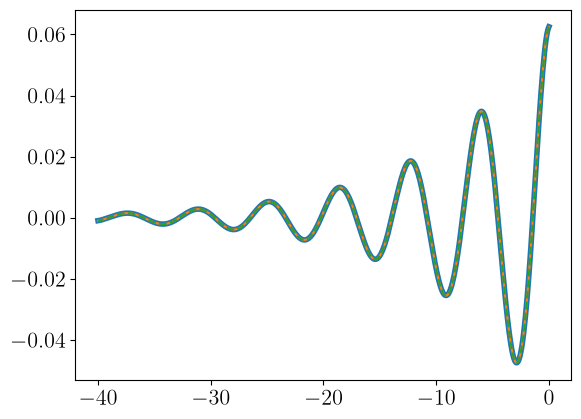

In [6]:
# Check behavior of fitted correlation functions at negative times 
plt.plot(-tlist, bcf_fit_gtr(tlist, gL, LmbL), linewidth=4)
plt.plot(-tlist, bath.correlation_function_minus(tlist, Nk=100))
plt.plot(-tlist, bath.correlation_function_minus(tlist, Nk=3), linestyle='--')

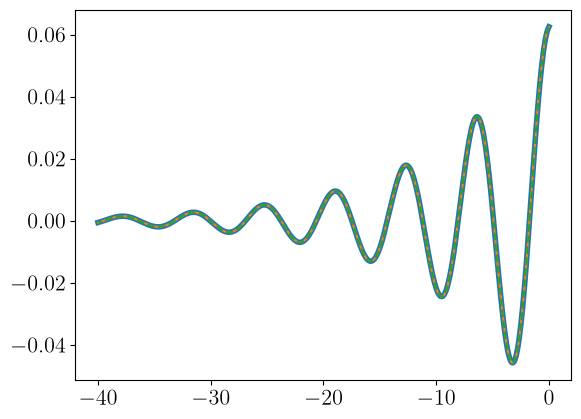

In [7]:
plt.plot(-tlist, bcf_fit_less(tlist, gR, LmbR), linewidth=4)
plt.plot(-tlist, bath.correlation_function_plus(-tlist, Nk=100))
plt.plot(-tlist, bath.correlation_function_plus(-tlist, Nk=3), linestyle='--')

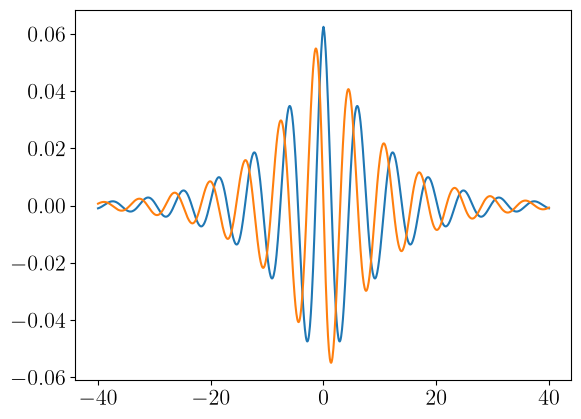

In [8]:
plt.plot(tlist_pn, np.real(bcf_fit_gtr(tlist_pn, gL, LmbL)))
plt.plot(tlist_pn, np.imag(bcf_fit_gtr(tlist_pn, gL, LmbL)))

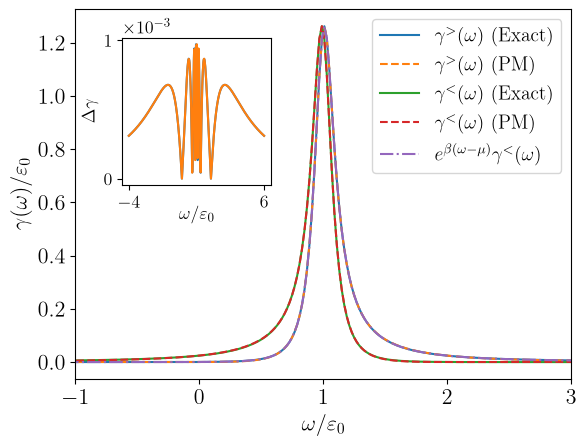

In [9]:
from pseudomodes.fitting import ps_fit_gtr, ps_fit_less

# Noise spectra
fig2, ax2 = plt.subplots()

ax2.plot(wlist, bath.power_spectrum_minus(wlist), label=r'$\gamma^{>}(\omega) \,\, (\mathrm{Exact})$')
ax2.plot(wlist, ps_fit_gtr(wlist, gL, LmbL), linestyle='--', label=r'$\gamma^{>}(\omega) \,\, (\mathrm{PM})$')
ax2.plot(wlist, bath.power_spectrum_plus(wlist), label=r'$\gamma^{<}(\omega) \,\, (\mathrm{Exact})$')
ax2.plot(wlist, ps_fit_less(wlist, gR, LmbR), linestyle='--', label=r'$\gamma^{<}(\omega) \,\, (\mathrm{PM})$')

ax2.set_ylabel(r'$\gamma(\omega) / \varepsilon_0$')
ax2.set_xlabel(r'$\omega / \varepsilon_0$')
ax2.set_xlim([-2+mu,2+mu])

# Check symmetry: gm_gtr = exp(beta*(w-mu))*gm_less
ax2.plot(wlist, np.exp((1./T)*(wlist - mu)) * bath.power_spectrum_plus(wlist), linestyle='-.', label=r'$e^{\beta(\omega-\mu)}\gamma^{<}(\omega)$')
ax2.legend(loc=1)

# Error
ps_gtr_err = np.abs(bath.power_spectrum_minus(wlist) - ps_fit_gtr(wlist, gL, LmbL))
ps_less_err = np.abs(bath.power_spectrum_plus(wlist) - ps_fit_less(wlist, gR, LmbR))

ax2_inset = inset_axes(ax2, width='100%', height='100%', 
                       loc='upper left', 
                       bbox_to_anchor=(0.075, 0.55, 0.3, 0.4),
                       bbox_transform=ax2.transAxes)

ax2_inset.plot(wlist, ps_gtr_err)
ax2_inset.plot(wlist, ps_less_err)

ax2_inset.tick_params(labelsize=13)
ax2_inset.set_xticks([min(wlist), max(wlist)])
ax2_inset.set_yticks([0, np.round(np.max(ps_gtr_err), 3)])
ax2_inset.set_ylabel(r'$\Delta\gamma$', fontsize=13)
ax2_inset.set_xlabel(r'$\omega / \varepsilon_0$', fontsize=13, labelpad=-4)

ax2_inset.ticklabel_format(style='sci', axis='y', scilimits=(0, 0), useMathText=True)
ax2_inset.yaxis.get_offset_text().set_fontsize(13)

plt.show()

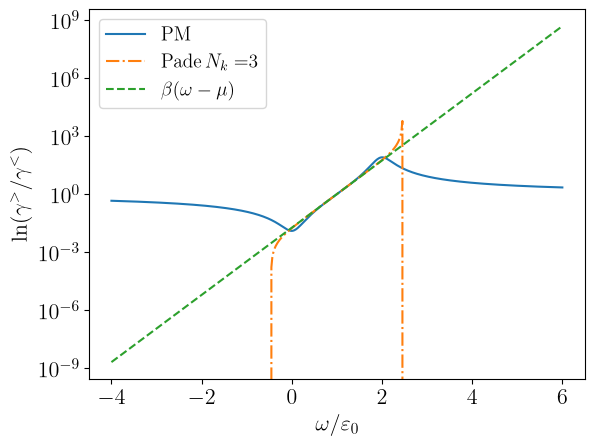

In [10]:
# Check detailed balance condition
Nk = 3
plt.semilogy(wlist, (ps_fit_gtr(wlist, gL, LmbL) / ps_fit_less(wlist, gR, LmbR)), label=r'$\mathrm{PM}$')
plt.semilogy(wlist, (bath.approx_by_matsubara(Nk=3).power_spectrum_minus(wlist) / bath.approx_by_matsubara(Nk=Nk).power_spectrum_plus(wlist)), 
         linestyle='-.',
         label=r'$\mathrm{Pade \,} N_k=$' + r'${0}$'.format(Nk))
plt.semilogy(wlist, np.exp((1./T) * (wlist - mu)), linestyle='--', label=r'$\beta(\omega-\mu)$')

plt.xlabel(r'$\omega/\varepsilon_0$')
plt.ylabel(r'$\mathrm{ln}(\gamma^>/\gamma^<)$')
plt.legend()


In [11]:
# Print fitted parameters
print('gL = {0}\n'.format(np.round(gL, 5)))
print('gR = {0}\n'.format(np.round(gR, 5)))

print('LmbL = \n {0}'.format(np.round(LmbL, 5)), '\n')

print('LmbR = \n {0}'.format(np.round(LmbR, 5)))

gL = [0.25118-0.02435j 0.07821+0.07821j]

gR = [0.07821-0.07821j 0.25118+0.02435j]

LmbL = 
 [[1.00047-0.09991j 0.     +0.j     ]
 [0.     +0.j      0.99997-1.00539j]] 

LmbR = 
 [[1.00003-1.00539j 0.     +0.j     ]
 [0.     +0.j      0.99953-0.09991j]]


----------

TRY SEPARATELY FITTING MATSUBARA AND NON-MATUSBARA PARTS OF SPECTURM? 

In [12]:
from pseudomodes.fitting import ps_fit_params_fermion

(gL_test, LmbL_test), (gR_test, LmbR_test) = ps_fit_params_fermion(wlist, 
                                                               sd=bath.spectral_density(wlist), 
                                                               T=T,
                                                               mu=mu,
                                                               init_params_gtr=([1,1,-1],[1,1,-1],[1,-1,-1,-1],[1,1,1,1]), 
                                                               init_params_less=([1,1,-1],[1,1,-1],[1,-1,-1,-1],[1,1,1,1]),
                                                               C0=(c0,c0,c0,c0))

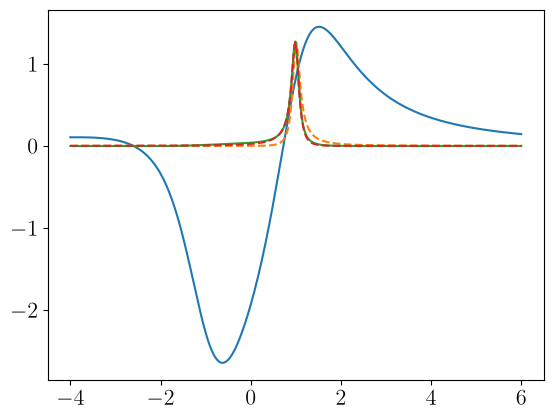

In [13]:
plt.plot(wlist, ps_fit_gtr(wlist, gL_test, LmbL_test))
plt.plot(wlist, bath.power_spectrum_minus(wlist), linestyle='--')
plt.plot(wlist, ps_fit_less(wlist, gR_test, LmbR_test))
plt.plot(wlist, bath.power_spectrum_plus(wlist), linestyle='--')

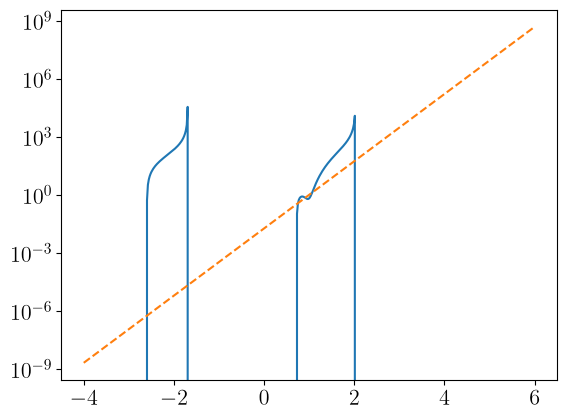

In [14]:
plt.semilogy(wlist, (ps_fit_gtr(wlist, gL_test, LmbL_test) / ps_fit_less(wlist, gR_test, LmbR_test)))
plt.semilogy(wlist, np.exp((1./T) * (wlist - mu)), linestyle='--', label=r'$\beta(\omega-\mu)$')


In [15]:
print('gL_test = {0}\n'.format(np.round(gL_test, 5)))
print('LmbL_test = {0}\n'.format(np.round(LmbL_test, 5)))
print('gR_test = {0}\n'.format(np.round(gR_test, 5)))
print('LmbR_test = {0}\n'.format(np.round(LmbR_test, 5)))

gL_test = [1.09868-0.45509j 1.09868-0.45509j 0.45509+1.09868j 0.46542+1.0743j ]

LmbL_test = [[ 1.-1.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j -1.-1.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j -1.-1.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.-1.j]]

gR_test = [0.25065+0.0174j  1.09868-0.45509j 0.45509+1.09868j 0.06595-0.06613j]

LmbR_test = [[ 0.9947-0.09919j  0.    +0.j       0.    +0.j       0.    +0.j     ]
 [ 0.    +0.j      -1.    -1.j       0.    +0.j       0.    +0.j     ]
 [ 0.    +0.j       0.    +0.j      -1.    -1.j       0.    +0.j     ]
 [ 0.    +0.j       0.    +0.j       0.    +0.j      -1.    -1.j     ]]



----------

## Extraction of PM parameters

The PM parameters are extracted through the following gauge transformation
\begin{equation*}
    \boldsymbol{g}'_j = \boldsymbol{U}_j\boldsymbol{g}_j, \qquad \boldsymbol{Z}_j = \boldsymbol{U}_j\boldsymbol{\Lambda}_j\boldsymbol{U}^T_j, \qquad j\in\{L,R\},
\end{equation*}
where the choice of gauge $\boldsymbol{U}_j = \boldsymbol{O}_je^{i\boldsymbol{R}_j}$ is fixed such that 
\begin{align*} 
    \boldsymbol{g}'_j &= \frac{1}{\sqrt{2(\eta_j + 1)}}\boldsymbol{O}_j(\boldsymbol{g}_j + \boldsymbol{g}^*_j), \\ 
    \boldsymbol{\xi}_j &= \frac{1}{2}\boldsymbol{O}_j\big(e^{i\boldsymbol{R}_j}\boldsymbol{\Lambda}_je^{-i\boldsymbol{R}_j} + {\rm c.c.}\big)\boldsymbol{O}^T_j, \\
        \boldsymbol{\gamma}_j &= \,i\boldsymbol{O}_j\big(e^{i\boldsymbol{R}_j}\boldsymbol{\Lambda}_je^{-i\boldsymbol{R}_j} - {\rm c.c.}\big)\boldsymbol{O}^T_j,
\end{align*}
with $\eta_j = \boldsymbol{g}^{\dagger}_j\boldsymbol{g}_j >0$. 

Note that $\boldsymbol{O}_j$ are chosen to ensure the Kossakowski matrix $\boldsymbol{\gamma}_j$ is diagonal.

In [16]:
from pseudomodes.fitting import pm_parameters

# Residues + pole locations
rLk = 1j*gL**2
zLk = LmbL

gpL, xiL, gmL, infoL = pm_parameters(rk=rLk, zk=zLk, info=True)

print('Greater:')
print('--------')
print(infoL['all'])
print('\n')

rRk = 1j*gR**2
zRk = LmbR

gpR, xiR, gmR, infoR = pm_parameters(rk=rRk, zk=zRk, info=True)

print('Lesser:')
print('--------')
print(infoR['all'])

Greater:
--------
gp = 
 [-0.23868 -0.07436]

xi = 
 [[1.00042 0.31221]
 [0.31221 1.00001]]

gm = 
 [0.00539 2.20521]


Lesser:
--------
gp = 
 [0.07436 0.23868]

xi = 
 [[ 0.99999 -0.31221]
 [-0.31221  0.99958]]

gm = 
 [2.20521 0.00539]


Check free PM correlation functions reproduce analytical results:

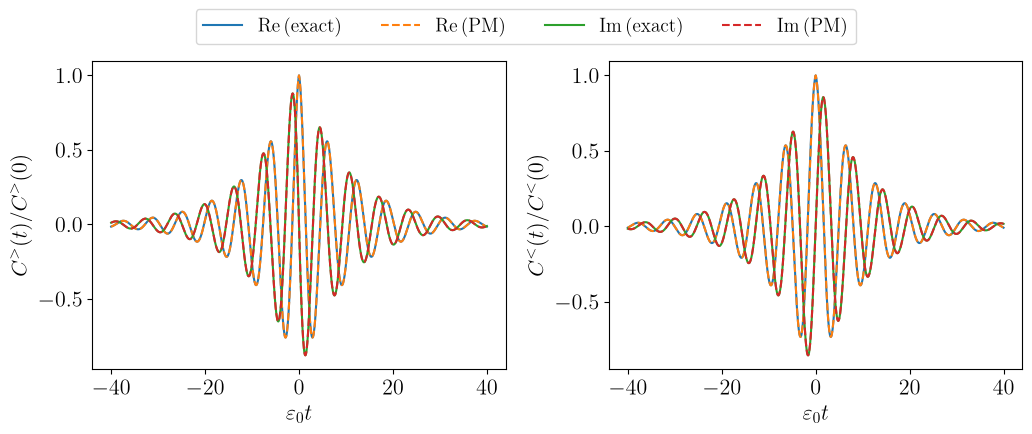

In [17]:
fig3, ax3 = plt.subplots(1,2, figsize=(12,4)) 

ZL = xiL - 0.5j*gmL
ZR = xiR - 0.5j*gmR

# Greater 
ax3[0].plot(tlist_pn, np.real(bcf_gtr) / c0, label=r'$\mathrm{Re \, (exact)}$')
ax3[0].plot(tlist_pn, np.real(bcf_fit_gtr(tlist_pn, gpL, ZL)) / c0, linestyle='--', label=r'$\mathrm{Re \, (PM)}$')
ax3[0].plot(tlist_pn, np.imag(bcf_gtr) / c0, label=r'$\mathrm{Im \, (exact)}$')
ax3[0].plot(tlist_pn, np.imag(bcf_fit_gtr(tlist_pn, gpL, ZL)) / c0, linestyle='--', label=r'$\mathrm{Im \, (PM)}$')

ax3[0].set_ylabel(r'$C^{>}(t) / C^{>}(0)$')
ax3[0].set_xlabel(r'$\varepsilon_0 t$')

# Lesser 
ax3[1].plot(tlist_pn, np.real(bcf_less) / c0, label=r'$\mathrm{Re \, (exact)}$')
ax3[1].plot(tlist_pn, np.real(bcf_fit_less(tlist_pn, gpR, ZR)) / c0, linestyle='--', label=r'$\mathrm{Re \, (PM)}$')
ax3[1].plot(tlist_pn, np.imag(bcf_less) / c0, label=r'$\mathrm{Im \, (exact)}$')
ax3[1].plot(tlist_pn, np.imag(bcf_fit_less(tlist_pn, gpR, ZR)) / c0, linestyle='--', label=r'$\mathrm{Im \, (PM)}$')

ax3[1].set_ylabel(r'$C^{<}(t) / C^{<}(0)$')
ax3[1].set_xlabel(r'$\varepsilon_0 t$')
ax3[1].legend(loc=0, ncols=4, bbox_to_anchor=(0.62, 1.2))

fig3.subplots_adjust(wspace=0.25)

plt.show()

## PMME simulation: single impurity Anderson model (SIAM)

We proceed to benchmark the PMME against the analytical results of the spinless SIAM, where $c_{\sigma}\rightarrow c$ and $d_{\sigma k}\rightarrow d_{k}$.

In this case the onsite interaction term vanishes, $c^{\dagger}cc^{\dagger}c = n^2 = 0$.

The PMME reads
\begin{equation*}
    \dot{\rho} = \mathcal{L}(\rho) = -i[H',\rho] + \sum_{j=L,R}\mathcal{D}_j(\rho),
\end{equation*}
with 
\begin{equation*}
    H' = \varepsilon_0c^{\dagger}c + \sum_{j=L,R}\Big[\sum^{N_j}_{k,l=1}\xi_{kl}f^{\dagger}_{jk}f_{jl} + \sum^{N_j}_{l=1}g'_{jl}(c^{\dagger}f_{jk} + {\rm h.c.})\Big],
\end{equation*}
and
\begin{align*}
    &\mathcal{D}_L(\rho) = \sum^{N_L}_{k,l=1}\gamma_{kl}\Big(f_{Ll}\rho f^{\dagger}_{Lk} - \tfrac{1}{2}\{f^{\dagger}_{Lk}f_{Ll},\rho\}\Big),    \\ 
    &\mathcal{D}_R(\rho) = \sum^{N_R}_{k,l=1}\gamma_{kl}\Big(f^{\dagger}_{Rk}\rho f_{Rl} - \tfrac{1}{2}\{f_{Rl}f^{\dagger}_{Rk},\rho\}\Big).  
\end{align*}

Note that the ordering of indices in each dissipator is consistent with that used in the Supp. Mat. of Huang ${\it et \, al.,}$ arXiv:2506.10308 (2025). 

In [19]:
from pseudomodes.siam import impurity_site_occ, pmme_fermion

# Check behavior of analytical solution 
times = np.linspace(0, 40, 500)
eps = 2

nt = impurity_site_occ(times, e0=eps, T=T, coup=lmb, width=W, w_res=mu, init_occ=1)

/Users/GraemePleasance/Documents/PM theory 2/Python/pseudomodes/siam.py:300: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  return quad(integrand, -np.inf, np.inf, args=t)[0]


In [20]:
# Initial system + PM state
NL, NR = 2, 2  # No. of PMs for greater/lesser env
init_state = qt.tensor([qt.ket2dm(qt.fock(2,1))] + [qt.fock_dm(2)] * NL + [qt.fock_dm(2,1)] * NR)

c = qt.destroy(2)
H_sys = eps * c.dag() * c

L_sys_pm = pmme_fermion(H_sys=H_sys, c_ops=c, pm_sys_coup=(gpL,gpR), pm_self=(xiL,xiR), pm_decay=(gmL,gmR)) 

In [21]:
# Solve PMME
n_op = qt.tensor([c.dag()*c] + [qt.identity(2)] * NL + [qt.identity(2)] * NR)

pm_pops = [qt.tensor([qt.identity(2)] + [qt.create(2) * qt.destroy(2) if idx == n else qt.identity(2) for idx in range(NL + NR)]) for n in range(NL + NR)]

result_pm = qt.mesolve(L_sys_pm, init_state, times, e_ops=[n_op] + pm_pops, options={'progress_bar': True})

10.0%. Run time:   0.02s. Est. time left: 00:00:00:00
20.0%. Run time:   0.02s. Est. time left: 00:00:00:00
30.1%. Run time:   0.03s. Est. time left: 00:00:00:00
40.1%. Run time:   0.04s. Est. time left: 00:00:00:00
50.1%. Run time:   0.05s. Est. time left: 00:00:00:00
60.1%. Run time:   0.06s. Est. time left: 00:00:00:00
70.1%. Run time:   0.06s. Est. time left: 00:00:00:00
80.2%. Run time:   0.07s. Est. time left: 00:00:00:00
90.2%. Run time:   0.07s. Est. time left: 00:00:00:00
100.0%. Run time:   0.08s. Est. time left: 00:00:00:00
Total run time:   0.08s


In [22]:
# HEOM 
from qutip.solver.heom import HEOMSolver

bath_approx = bath.approx_by_pade(Nk=3)  # EDIT - check if possible to use fitted bcf rather than pade expansion? 
rho_sys = init_state.ptrace([0])

max_depth = 5 
options = {"nsteps": 15_000} 
solver = HEOMSolver(H_sys, (bath_approx, c), max_depth=max_depth, options=options)
result = solver.run(rho_sys, times, e_ops=c.dag()*c)

10.0%. Run time:   0.00s. Est. time left: 00:00:00:00
20.0%. Run time:   0.01s. Est. time left: 00:00:00:00
30.1%. Run time:   0.01s. Est. time left: 00:00:00:00
40.1%. Run time:   0.02s. Est. time left: 00:00:00:00
50.1%. Run time:   0.03s. Est. time left: 00:00:00:00
60.1%. Run time:   0.03s. Est. time left: 00:00:00:00
70.1%. Run time:   0.04s. Est. time left: 00:00:00:00
80.2%. Run time:   0.05s. Est. time left: 00:00:00:00
90.2%. Run time:   0.06s. Est. time left: 00:00:00:00
100.0%. Run time:   0.07s. Est. time left: 00:00:00:00
Total run time:   0.07s


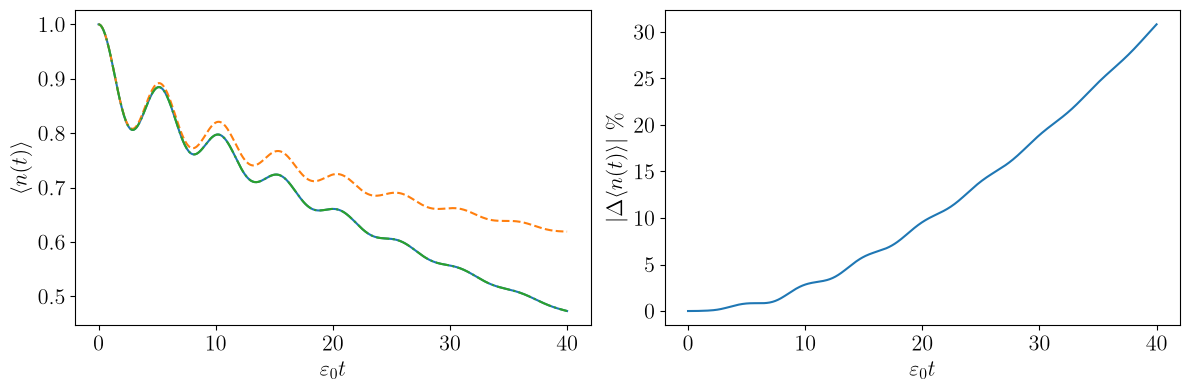

In [23]:
# Plot impurity site occupation
fig4, ax4 = plt.subplots(1, 2, figsize=(12,4))

ax4[0].plot(times, nt, label=r'$\mathrm{Exact}$')
ax4[0].plot(times, result_pm.expect[0], linestyle='--', label=r'$\mathrm{PM}$')
ax4[0].plot(times, result.expect[0], linestyle='-.', label=r'$\mathrm{HEOM}$')

ax4[0].set_ylabel(r'$\langle n(t)\rangle$')
ax4[0].set_xlabel(r'$\varepsilon_0 t$')

rel_error_siam = 100 * np.abs(result_pm.expect[0] - nt) / (np.abs(nt))

ax4[1].plot(times, rel_error_siam)
ax4[1].set_ylabel(r'$|\Delta\langle n(t)\rangle| \,\, \%$')
ax4[1].set_xlabel(r'$\varepsilon_0t$')

fig4.tight_layout()

Text(0.5, 0, '$\\varepsilon_0t$')

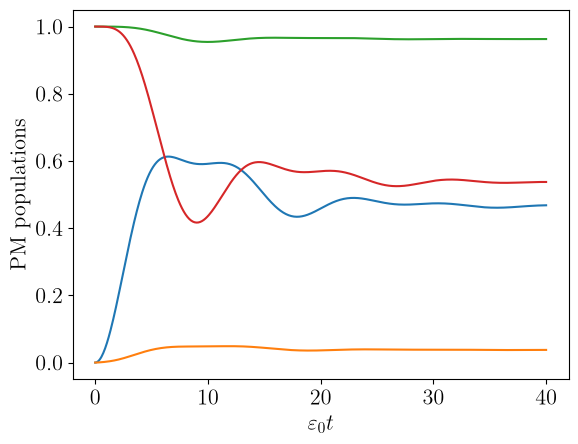

In [66]:
# Plot PM populations 
fig5, ax5 = plt.subplots()

for n in range(len(pm_pops)):
    ax5.plot(times, result_pm.expect[n+1])

ax5.set_ylabel(r'$\mathrm{PM \,\, populations}$')
ax5.set_xlabel(r'$\varepsilon_0t$')

In [15]:
import json 

# Save simulation data
np.save('data/fermionic/numpy/site_occ_exact_beta_' + str(1./T) + '.npy', nt)
np.save('data/fermionic/numpy/site_occ_beta_' + str(1./T) + '.npy', result_pm.expect[0])

np.savetxt('data/fermionic/site_occ_exact_beta_' + str(1./T) + '.npy', 
           np.column_stack([times, nt]),
           header='x y', 
           comments='', 
           fmt='%.8f'
           )
np.savetxt('data/fermionic/site_occ_pm_beta_' + str(1./T) + '.txt', 
           np.column_stack([times, result_pm.expect[0]]), 
           header='x y', 
           comments='', 
           fmt='%.8f'
           )

# PM populations
np.save('data/fermionic/numpy/site_occ_pm_pop_gtr_1_beta_' + str(1./T) + '.npy', result_pm.expect[1])
np.save('data/fermionic/numpy/site_occ_pm_pop_gtr_2_beta_' + str(1./T) + '.npy', result_pm.expect[2])
np.save('data/fermionic/numpy/site_occ_pm_pop_less_1_beta_' + str(1./T) + '.npy', result_pm.expect[3])
np.save('data/fermionic/numpy/site_occ_pm_pop_less_2_beta_' + str(1./T) + '.npy', result_pm.expect[4])

np.savetxt('data/fermionic/site_occ_pm_pop_gtr_1_beta_' + str(1./T) + '.txt',
           np.column_stack([times, result_pm.expect[1]]), 
           header='x y', 
           comments='', 
           fmt='%.8f'
           )
np.savetxt('data/fermionic/site_occ_pm_pop_gtr_2_beta_' + str(1./T) + '.txt',
           np.column_stack([times, result_pm.expect[2]]), 
           header='x y', 
           comments='', 
           fmt='%.8f'
           )
np.savetxt('data/fermionic/site_occ_pm_pop_less_1_beta_' + str(1./T) + '.txt',
           np.column_stack([times, result_pm.expect[3]]), 
           header='x y', 
           comments='', 
           fmt='%.8f')
np.savetxt('data/fermionic/site_occ_pm_pop_less_2_beta_' + str(1./T) + '.txt',
           np.column_stack([times, result_pm.expect[4]]), 
           header='x y', 
           comments='', 
           fmt='%.8f')

# Save metadata
params_dict = {'Temperature': T, 
               'Chemical potential': mu, 
               'Coupling': lmb, 
               'Width': W,
               'Energy splitting': eps, 
               'Max. time': times[-1], 
               'Times_len': len(times)
               }

params_dict_pm = {'No. pseudomodes (greater)': NL,
                  'No. pseudomodes (lesser)' : NR
                  }

metadata = {
    'Parameters': params_dict,
    'Pseudomode parameters': params_dict_pm
}

with open ('data/fermionic/metadata_beta_' + str(1./T) + '.json', 'w') as f:
    json.dump(metadata, f, indent=4)

In [16]:
np.save('data/fermionic/numpy/site_occ_error_beta_' + str(1./T) + '.npy', rel_error_siam)

np.savetxt('data/fermionic/site_occ_error_beta_' + str(1./T) + '.txt', 
           np.column_stack([times, rel_error_siam]),
           header='x y', 
           comments='', 
           fmt='%.8f'
           )

## Liouvillian spectrum

Since the generator $\mathcal{L}$ does not preserve the complete positivity of the dynamics (negative $\boldsymbol{\gamma}_{L/R}$), it is possible for $\mathcal{L}$ to admit complex eigenvalues with positive real parts. 
These positive components grow exponentially in the long-time limit and therefore define an unstable dynamics.

The PMME will be asymptotically stable if and only if  
\begin{equation*}
    \alpha \leq 0,
\end{equation*}
where $\alpha = {\rm sup}({\rm Re}[\sigma(\mathcal{L})])$ defines the maximum real part of the eigevanlues of $\mathcal{L}$, also known as the spectral abscissa of $\mathcal{L}$. 

Connection to Lyapunov exponents?

In [17]:
spec_sys_pm = L_sys_pm.eigenenergies()

Text(0, 0.5, '$\\mathrm{Im}[\\lambda_i]$')

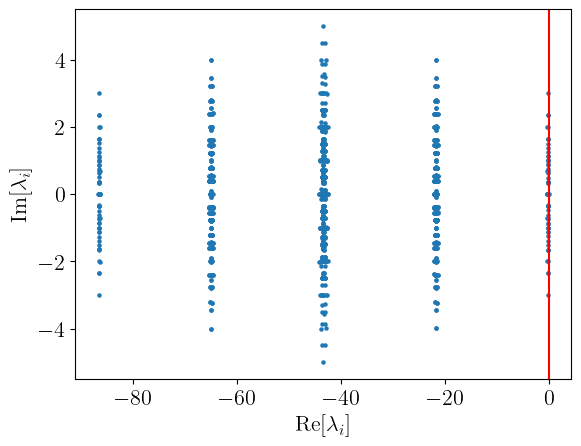

In [18]:
# Scatter plot of Liouvillian spectrum
fig6, ax6 = plt.subplots()

ax6.scatter(np.real(spec_sys_pm), np.imag(spec_sys_pm), s=5)

ax6.axvline(x=0, c='r')
ax6.set_xlabel(r'$\mathrm{Re}[\lambda_i]$')
ax6.set_ylabel(r'$\mathrm{Im}[\lambda_i]$')

# Print spectral abscissa 

In [19]:
spec_real = np.real(spec_sys_pm)
spec_imag = np.imag(spec_sys_pm)

np.save('data/fermionic/numpy/site_occ_pmme_spectrum_beta_' + str(1./T) + '.npy', spec_sys_pm)

np.savetxt('data/fermionic/site_occ_pmme_spectrum_beta_' + str(1./T) + '.txt', 
           np.column_stack([spec_real, spec_imag]),
           header='x y', 
           comments='', 
           fmt='%.8f'
           )

### Also benchmark against weak coupling result? ($W\rightarrow\infty$)


## Kondo Resonance

For the `spinful' SIAM, we are interested in evaluating the spectral function 
\begin{equation*}
    A(\omega) = -\frac{1}{\pi}{\rm Im}\,G^R(\omega).
\end{equation*}
Here, $G^R(\omega) = \int d\omega\,G^R(t)e^{i\omega t}$, and
\begin{equation*}
G^R(t)= -i\langle\{c(t),c^{\dagger}(0)\}\rangle_{\rm ss}
\end{equation*}
is the retarded Green's function of the impurity in the steady state, i.e., $\langle\cdot\rangle_{\rm ss} := {\rm Tr}[\cdot\rho_{\rm ss}]$, with $\mathcal{L}\rho_{\rm ss} =0$. 

The spectral function $A(\omega)$ defines the probability density of adding (removing) a particle of energy $\omega$ ($-\omega$) to the impurity site at $t=0$ and removing (adding) another particle from (to) the same site at $t>0$. Hence, it admits unit normalization $\int d\omega\,A(\omega) = 1$.

In [20]:
# Spinful SIAM with nonvanishing onsite interaction U
U = -2  # units of e0

c_up = np.tensor(np.destroy(2), np.identity(2))
c_down = np.tensor(np.identity(2), np.destroy(2))

# Construct Liouvillian 
H_sys = eps * (c_up.dag() * c_up + c_down.dag() * c_down)

L_sys_pm = pmme_fermion(H_sys=H_sys, c_ops=(c_up+c_down), pm_sys_coup=(gpL,gpR), pm_self=(xiL,-xiR), pm_decay=(gmL,gmR))

AttributeError: module 'numpy' has no attribute 'tensor'

In [ ]:
# Steady state
state_ss = qt.steadystate(L_sys_pm)

How to evaluate Green's function for +ve/-ve times...

In [ ]:
# Green's function solver
solver = qt.MESolver(L_sys_pm, options={'progress_bar': True}) 

# Greater projection
qt.correlation_3op(solver=solver,
                   state0=state_ss,
                   )

# Lesser projection (Hermitian conjugate?)